# Generalização e dimensionalidade

## Importando bibliotecas e os dados

In [16]:
import os
import sys
sys.path.append("..")

os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.knn_utils import escalar, criar_rodar, criar_cv_f1, razao_distancias

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda v: f"{v:.4f}")


df = pd.read_csv("../data/raw/dupla_08.csv")


In [17]:
X = df.drop(columns="classe")

train_df = pd.read_csv("../data/processed/train.csv", index_col="id")
test_df = pd.read_csv("../data/processed/test.csv", index_col="id")
X_train, y_train = train_df.drop(columns="classe"), train_df["classe"]
X_test, y_test = test_df.drop(columns="classe"), test_df["classe"]

rodar = criar_rodar(X_train, X_test, y_train, y_test)
cv_f1 = criar_cv_f1(X_train, y_train)

k_teste = pd.read_csv("../data/processed/k_teste.csv", index_col="k")
votacao = pd.read_csv("../data/processed/votacao.csv", index_col="pesos")
votacao_cv = pd.read_csv("../data/processed/votacao_cv.csv", index_col="pesos")
ks = list(k_teste.index)

## Análise de generalização

Escolhemos três configurações que apareceram como interessantes nos experimentos anteriores. A coluna de validação cruzada (5 dobras, só no treino) foi acrescentada como uma segunda fonte de evidência sobre a estabilidade de cada uma.

- **A:** MinMax, k = 15, euclidiana, votação uniforme (melhor equilíbrio).
- **B:** MinMax, k = 15, euclidiana, votação ponderada (maior F1 de teste entre as duas votações).
- **C:** MinMax, k = 7, Manhattan, votação uniforme (bom resultado com k menor e outra métrica).

In [18]:
candidatas = {
    "A": dict(tipo="minmax", k=15, p=2, pesos="uniform"),
    "B": dict(tipo="minmax", k=15, p=2, pesos="distance"),
    "C": dict(tipo="minmax", k=7,  p=1, pesos="uniform"),
}

da_parte5 = {"A": "uniform", "B": "distance"}
nomes_dist = {1: "Manhattan", 2: "Euclidiana"}
linhas = []
for nome, cfg in candidatas.items():
    if nome in da_parte5:
        r = votacao.loc[da_parte5[nome]]
        m_cv, s_cv = votacao_cv.loc[da_parte5[nome]]
    else:
        r = rodar(**cfg)
        m_cv, s_cv = cv_f1(cfg["tipo"], cfg["k"], cfg["p"], cfg["pesos"])
    linhas.append({"Modelo": nome, "Escalonamento": "MinMax", "k": cfg["k"],
                   "Distância": nomes_dist[cfg["p"]], "Pesos": cfg["pesos"],
                   "F1 treino": r["f1_treino"], "F1 teste": r["f1_teste"], "Gap": r["gap"],
                   "F1 cv (média)": m_cv, "F1 cv (desvio)": s_cv})
tab_cand = pd.DataFrame(linhas).set_index("Modelo")
tab_cand

,Escalonamento,k,Distância,Pesos,F1 treino,F1 teste,Gap,F1 cv (média),F1 cv (desvio)
Modelo,,,,,,,,,
A,MinMax,15,Euclidiana,uniform,0.8230,0.8187,0.0042,0.7821,0.0230
B,MinMax,15,Euclidiana,distance,1.0000,0.8253,0.1747,0.7821,0.0250
C,MinMax,7,Manhattan,uniform,0.8556,0.8184,0.0372,0.7950,0.0193


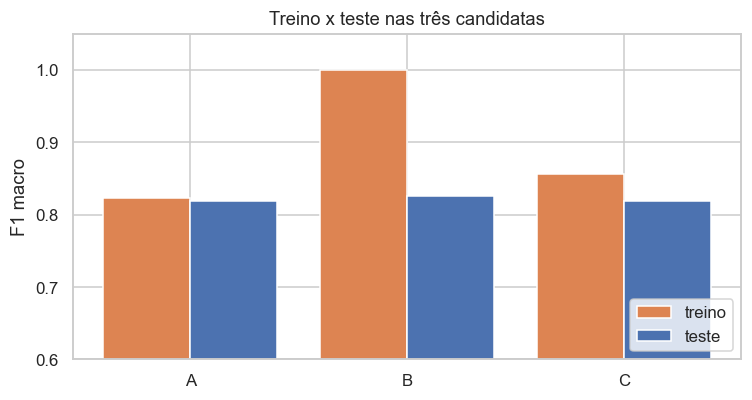

In [19]:
fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(tab_cand))
ax.bar(x - 0.2, tab_cand["F1 treino"], 0.4, label="treino", color="#DD8452")
ax.bar(x + 0.2, tab_cand["F1 teste"], 0.4, label="teste", color="#4C72B0")
ax.set_xticks(x)
ax.set_xticklabels(tab_cand.index)
ax.set_ylim(0.6, 1.05)
ax.set_ylabel("F1 macro")
ax.set_title("Treino x teste nas três candidatas")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Resultado da análise

* Maior F1 no treino não significa melhor modelo: B chegou a 1,000, indicando possível overfitting.
* No teste, B teve 0,825 contra 0,819 de A, uma diferença pequena.
* A teve o menor gap: 0,004, contra 0,175 em B e 0,037 em C.
* C teve a melhor validação cruzada (0,795) e o menor desvio (0,019), mas um gap maior que o de A.
* A foi escolhida pelo melhor equilíbrio entre estabilidade e desempenho.

## Investigação da dimensionalidade

Adicionamos dez atributos aleatórios (uniformes entre 0 e 1, sem relação com a classe) e repetimos a avaliação com a configuração A. O escalonador continua sendo ajustado só no treino.

In [20]:
X_ruido = X.copy()
rng = np.random.default_rng(42)
for i in range(10):
    X_ruido[f"ruido_{i}"] = rng.random(len(X_ruido))

Xr_train, Xr_test = X_ruido.loc[X_train.index], X_ruido.loc[X_test.index]
print(X_ruido.shape, "| mesmas linhas de treino/teste:", (Xr_train.index == X_train.index).all())

antes = votacao.loc["uniform"].to_dict()
depois = rodar("minmax", k=15, p=2, pesos="uniform", X_a=Xr_train, X_b=Xr_test)
tab_dim = pd.DataFrame({"9 atributos originais": antes, "19 atributos (com ruído)": depois}).T[["f1_treino", "f1_teste", "gap", "acc_teste", "prec_teste", "rec_teste"]]
tab_dim.columns = ["F1 treino", "F1 teste", "Gap", "Acurácia teste", "Precision teste", "Recall teste"]
tab_dim

(620, 19) | mesmas linhas de treino/teste: True


,F1 treino,F1 teste,Gap,Acurácia teste,Precision teste,Recall teste
9 atributos originais,0.8230,0.8187,0.0042,0.8194,0.8214,0.8185
19 atributos (com ruído),0.6868,0.6258,0.0611,0.6258,0.6259,0.6259


In [21]:
r_ant, d_ant = razao_distancias(X_train, X_test)
r_dep, d_dep = razao_distancias(Xr_train, Xr_test)
tab_razao = pd.DataFrame({"9 atributos": [r_ant, d_ant], "19 atributos": [r_dep, d_dep]},
                         index=["vizinho mais próximo / distância média", "distância média"])
tab_razao

,9 atributos,19 atributos
vizinho mais próximo / distância média,0.3137,0.5426
distância média,0.6963,1.4729


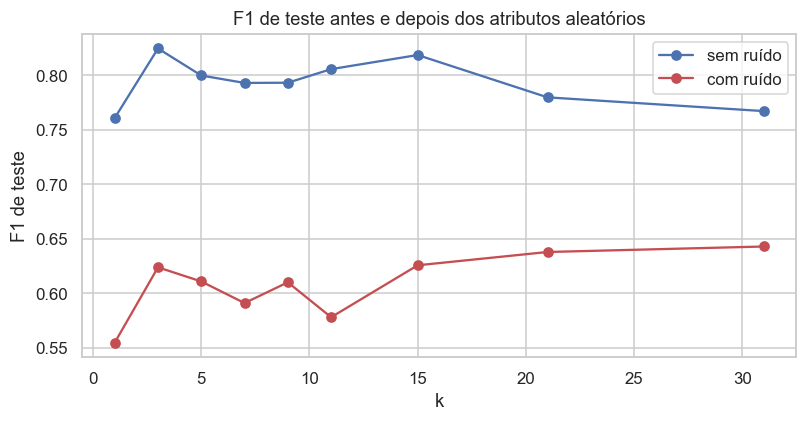

In [22]:
curva = pd.DataFrame({
    "sem ruído": k_teste["f1_teste"],
    "com ruído": [rodar("minmax", k=k, X_a=Xr_train, X_b=Xr_test)["f1_teste"] for k in ks],
}, index=pd.Index(ks, name="k"))

ax = curva.plot(marker="o", figsize=(7.5, 4), color=["#4C72B0", "#C44E52"])
ax.set_ylabel("F1 de teste")
ax.set_title("F1 de teste antes e depois dos atributos aleatórios")
plt.tight_layout()
plt.show()

### Resultado da investigação
* O desempenho piorou bastante: o F1 de teste caiu de 0,819 para 0,626.
* Mais atributos não significam mais informação. Os 10 novos eram aleatórios e só adicionaram ruído.
* Com mais dimensões, as distâncias ficam mais parecidas: a razão entre a distância ao vizinho mais próximo e a distância média subiu de 0,31 para 0,54, e o K-NN tem mais dificuldade para identificar os vizinhos.
* Isso é a maldição da dimensionalidade: com mais dimensões o espaço fica mais esparso e a diferença entre perto e longe some, e o K-NN depende desse contraste. 